# 03 - Speaker-Independent Train / Validation / Test Split

**Goal:** create one split file, `data/split.csv`, that **both team members use** so the SVM, Random Forest and CNN are compared on exactly the same test clips.

**Why split by actor:** RAVDESS has only 24 speakers, each saying the same two sentences. If clips from one actor appear in both train and test, a model can learn the actor's voice instead of the emotion and gets an inflated score. So whole actors are assigned to a single split.

**Design**
| Split | Actors | Purpose |
|---|---|---|
| Test | 1, 9, 12, 17, 19 | Final evaluation only (fixed by the team, also used by the classical-ML pipeline) |
| Validation | 3, 6, 15, 20 | Tuning and early stopping for the CNN |
| Train | the remaining 15 actors | Training |

## 0. Imports and setup

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("../images", exist_ok=True)
os.makedirs("../data", exist_ok=True)

EMOTIONS = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

## 1. Load cleaned metadata and define the split

In [2]:
df = pd.read_csv("../data/clean_metadata.csv")

TEST_ACTORS = [1, 9, 12, 17, 19]
VAL_ACTORS  = [3, 6, 15, 20]
assert set(TEST_ACTORS).isdisjoint(VAL_ACTORS), "an actor is in both test and validation"

def assign(actor):
    if actor in TEST_ACTORS: return "test"
    if actor in VAL_ACTORS:  return "val"
    return "train"

df["split"] = df["actor"].map(assign)
df["emotion_id"] = df["emotion_id"].astype(int)
print(df["split"].value_counts())

split
train    899
test     300
val      240
Name: count, dtype: int64


## 2. Sanity checks

In [3]:
# 1) every actor belongs to exactly one split
actor_splits = df.groupby("actor")["split"].nunique()
assert (actor_splits == 1).all(), "some actor appears in more than one split!"

# 2) no clip appears twice and every clip has a split
assert df["filename"].is_unique
assert df["split"].notna().all()

# 3) the three splits share no actors
sets = {s: set(df.loc[df["split"] == s, "actor"]) for s in ["train", "val", "test"]}
print({k: sorted(v) for k, v in sets.items()})
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("\nAll checks passed: the split is speaker-independent.")

{'train': [2, 4, 5, 7, 8, 10, 11, 13, 14, 16, 18, 21, 22, 23, 24], 'val': [3, 6, 15, 20], 'test': [1, 9, 12, 17, 19]}

All checks passed: the split is speaker-independent.


## 3. Size, gender and emotion balance in each split

In [4]:
print(df.groupby("split").agg(clips=("filename", "count"), actors=("actor", "nunique")))
print()
print(pd.crosstab(df["split"], df["gender"]))
print()
counts = pd.crosstab(df["split"], df["emotion"])[EMOTIONS]
print(counts)
print()
print((counts.div(counts.sum(axis=1), axis=0) * 100).round(1))

       clips  actors
split               
test     300       5
train    899      15
val      240       4

gender  female  male
split               
test        60   240
train      540   359
val        120   120

emotion  neutral  calm  happy  sad  angry  fearful  disgust  surprised
split                                                                 
test          20    40     40   40     40       40       40         40
train         60   120    119  120    120      120      120        120
val           16    32     32   32     32       32       32         32

emotion  neutral  calm  happy   sad  angry  fearful  disgust  surprised
split                                                                  
test         6.7  13.3   13.3  13.3   13.3     13.3     13.3       13.3
train        6.7  13.3   13.2  13.3   13.3     13.3     13.3       13.3
val          6.7  13.3   13.3  13.3   13.3     13.3     13.3       13.3


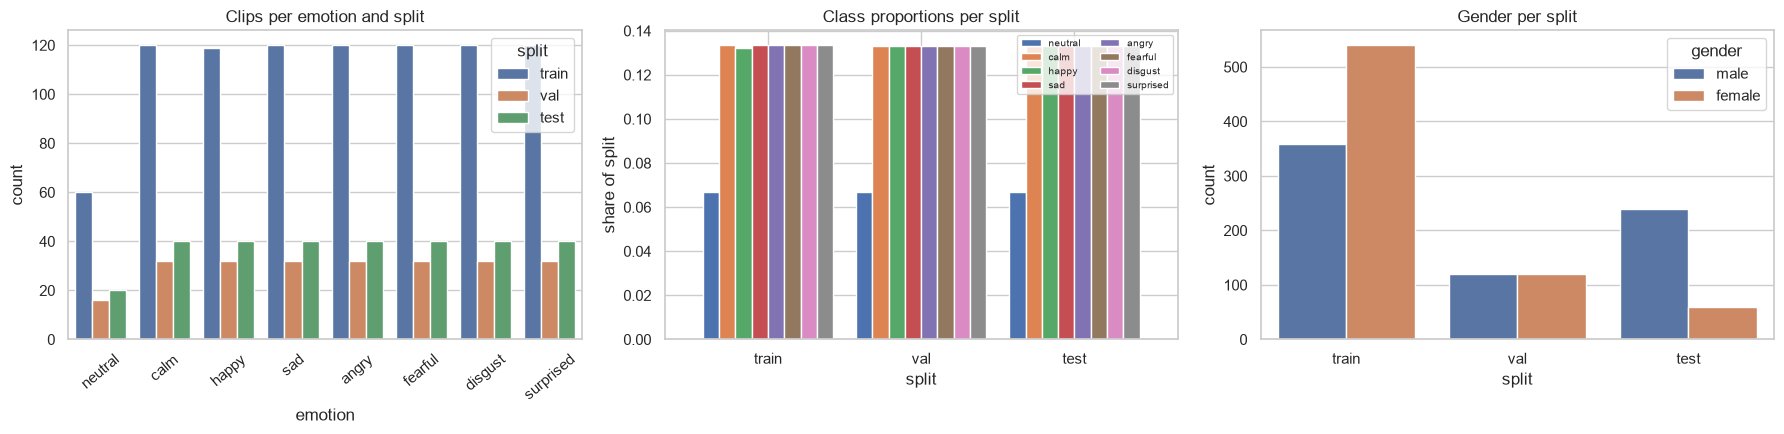

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
order = ["train", "val", "test"]
sns.countplot(data=df, x="emotion", hue="split", order=EMOTIONS, hue_order=order, ax=axes[0])
axes[0].set_title("Clips per emotion and split"); axes[0].tick_params(axis="x", rotation=40)

prop = (counts.div(counts.sum(axis=1), axis=0)).reindex(order)
prop.plot(kind="bar", ax=axes[1], width=0.85)
axes[1].set_title("Class proportions per split"); axes[1].set_ylabel("share of split")
axes[1].tick_params(axis="x", rotation=0); axes[1].legend(fontsize=7, ncol=2)

sns.countplot(data=df, x="split", hue="gender", order=order, ax=axes[2])
axes[2].set_title("Gender per split")
plt.tight_layout()
plt.savefig("../images/split_class_counts.png", dpi=140)
plt.show()

**What it shows**
- Class proportions are almost identical across splits (neutral is about 7% everywhere), because every actor records the same emotions. The split is not distorted by class imbalance.
- **The test set is gender-skewed: 4 male actors and only 1 female actor.** Test results therefore say more about male voices. This is a limitation that must be stated in the final report.
- The training set has the opposite tilt (more female than male actors). The validation set is built from 2 male and 2 female actors to keep tuning fair.

## 4. Save the split file

In [6]:
cols = ["filename", "actor", "gender", "emotion", "emotion_id", "intensity", "split"]
df[cols].to_csv("../data/split.csv", index=False)
print("saved ../data/split.csv ->", len(df), "rows")
pd.read_csv("../data/split.csv").head()

saved ../data/split.csv -> 1439 rows


,filename,actor,gender,emotion,emotion_id,intensity,split
0,03-01-01-01-01-01-01.wav,1,male,neutral,1,normal,test
1,03-01-01-01-01-02-01.wav,1,male,neutral,1,normal,test
2,03-01-01-01-02-01-01.wav,1,male,neutral,1,normal,test
3,03-01-01-01-02-02-01.wav,1,male,neutral,1,normal,test
4,03-01-02-01-01-01-01.wav,1,male,calm,2,normal,test
